In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl

In [3]:
df = pd.read_csv('rel_lc_TOI519.csv')
df

,Unnamed: 0,GJD-2450000,flux,err
0,0,8818.214705,1.006864,0.002557
1,1,8818.215422,1.001648,0.002534
2,2,8818.216140,0.999964,0.002608
3,3,8818.216846,1.000532,0.002580
4,4,8818.217564,1.003515,0.002646
...,...,...,...,...
215,215,8818.368490,0.995856,0.003269
216,216,8818.369207,1.002126,0.003383
217,217,8818.369925,0.996549,0.003573
218,218,8818.370631,0.992740,0.003558


- Mandel & Agol 2002 https://arxiv.org/pdf/astro-ph/0210099.pdf
- Kipping 2013 https://arxiv.org/pdf/1308.0009.pdf

# GJD to BJD

なんかうまくいかないのでネットでやってきます
https://astroutils.astronomy.osu.edu/time/hjd2bjd.html

In [4]:
df['GJD-2450000']+2450000

0      2.458818e+06
1      2.458818e+06
2      2.458818e+06
3      2.458818e+06
4      2.458818e+06
           ...     
215    2.458818e+06
216    2.458818e+06
217    2.458818e+06
218    2.458818e+06
219    2.458818e+06
Name: GJD-2450000, Length: 220, dtype: float64

In [5]:
np.array(df['GJD-2450000']+2450000)

array([2458818.214705, 2458818.215422, 2458818.21614 , 2458818.216846,
       2458818.217564, 2458818.218281, 2458818.218987, 2458818.219705,
       2458818.220422, 2458818.221128, 2458818.221846, 2458818.222564,
       2458818.22327 , 2458818.223987, 2458818.224693, 2458818.225411,
       2458818.226128, 2458818.226834, 2458818.227552, 2458818.22827 ,
       2458818.228976, 2458818.229693, 2458818.230399, 2458818.231117,
       2458818.231834, 2458818.232552, 2458818.233258, 2458818.233976,
       2458818.234693, 2458818.235399, 2458818.236117, 2458818.236834,
       2458818.237552, 2458818.238258, 2458818.238976, 2458818.239693,
       2458818.240399, 2458818.241117, 2458818.241834, 2458818.242541,
       2458818.243258, 2458818.243976, 2458818.244682, 2458818.245399,
       2458818.246105, 2458818.246823, 2458818.247541, 2458818.248258,
       2458818.248964, 2458818.249682, 2458818.250399, 2458818.251105,
       2458818.251823, 2458818.252541, 2458818.253258, 2458818.253964,
      

In [6]:
np.savetxt('TOI519_GJD.txt', np.array(df['GJD-2450000']+2450000), delimiter='\n', fmt='%.8f')

In [7]:
BJD=np.loadtxt('TOI519_BJD.txt', delimiter='\n')
df['BJD']=BJD

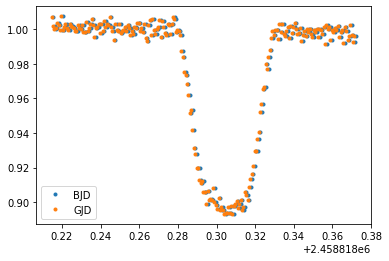

In [7]:
bjd = df['BJD']
flux = df['flux']
err = df['err']

#pl.errorbar(bjd, flux, err, fmt='.')

pl.plot(df['BJD'], df['flux'], '.', label='BJD')
pl.plot(df['GJD-2450000']+2450000, df['flux'], '.', label='GJD')
pl.legend()

In [8]:
(df['GJD-2450000']+2450000 - df['BJD'])*24*60

0     -1.205279
1     -1.205280
2     -1.205279
3     -1.205280
4     -1.205280
         ...   
215   -1.205280
216   -1.205280
217   -1.205280
218   -1.205280
219   -1.205280
Length: 220, dtype: float64

# imput parameters

https://exofop.ipac.caltech.edu/tess/target.php?id=218795833

In [9]:
from uncertainties import ufloat

ra = "08:18:25.62" 
dec ="-19:39:46.05"

k_pr = ufloat(0.3, 0.0091) #Rp/Rs
a_pr = ufloat(10.11, 0.14) #a/Rs
b_pr = ufloat(0.19, 0.06) 

In [10]:
T0_pr  = ufloat(2458491.8771169, 0.) 
P_pr    =  ufloat(1.2652328, 0.0000005)
num = np.ceil((df['BJD'][0] - T0_pr.n)/P_pr.n)
Tc_pr = T0_pr + num * P_pr
Tc_pr

2458818.3071793+/-0.000129

In [11]:
from ldtk import LDPSetCreator
from ldtk.filters import  sdss_g,sdss_r,sdss_i, sdss_z

teff, uteff = 3324,  157
feh, ufeh   = 0.0,  0.7 
logg,ulogg = 4.86877, 0.000630214

In [12]:
sc = LDPSetCreator(teff=(teff,uteff), logg=(logg,ulogg), z=(feh,ufeh), filters=[sdss_z])
ps = sc.create_profiles(nsamples=2000)
ps.resample_linear_z(100)
qd_c,qd_e = ps.coeffs_qd(do_mc=True, n_mc_samples=10000)

In [13]:
u1, u2 = list(qd_c[0])
u1e, u2e = list(qd_e[0])

# Transit Model

In [15]:
import batman

In [49]:
def transit_model(parameters, p, u1,u2, t):

    tc,a,b,k=parameters
    inc= np.arccos(b/a)*180/np.pi
    
    params = batman.TransitParams()
    params.t0 = tc                      #time of inferior conjunction
    params.per = p                     #orbital period
    params.rp = k                 #planet radius (in units of stellar radii)
    params.a = a                      #semi-major axis (in units of stellar radii)
    params.inc = inc                     #orbital inclination (in degrees)
    params.ecc = 0.                      #eccentricity
    params.w = 90.                       #longitude of periastron (in degrees)
    params.u = [u1, u2]                #limb darkening coefficients [u1, u2]
    params.limb_dark = "quadratic" 

    m = batman.TransitModel(params, np.array(t))  
    #for pallalization
    #m = batman.TransitModel(params, t, nthreads = 4)

    flux = m.light_curve(params)
    
    return flux

0.29508302582894474


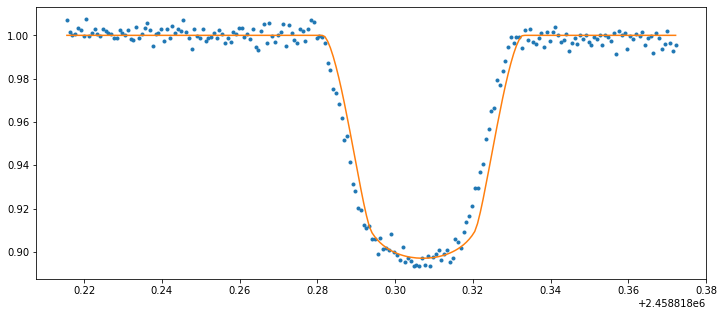

In [17]:
f=pl.figure(figsize=(12,5))

time =df['BJD']
flux=df['flux']

pl.plot(time,flux,'.')

transit_params_pr=[Tc_pr.n,a_pr.n,b_pr.n,k_pr.n]
transit_model_pr=transit_model(transit_params_pr, P_pr.n, u1, u2, time)
pl.plot(time,transit_model_pr)
print(u1)

# Simple systematic model 

In [57]:
c0_pr = 1.
c1_pr = -0.05
sys_params_pr = [c0_pr, c1_pr]

def sys_model(sys_params, t):
    c0, c1 = sys_params
    return  [c0]*len(t) + c1*(t-t[0])

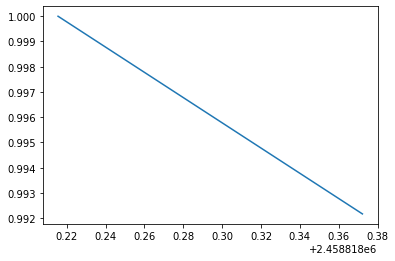

In [19]:
time = df['BJD']

sys_model_pr = sys_model(sys_params_pr,time)
pl.plot(time, sys_model_pr)

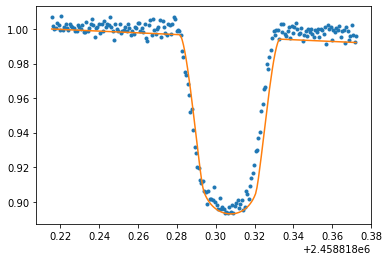

In [20]:
pl.plot(time,flux,'.')
pl.plot(time, sys_model_pr * transit_model_pr )

# preparing parameter set

In [23]:
params_full_pr = transit_params_pr + sys_params_pr
params_full_pr

[2458818.3071793, 10.11, 0.19, 0.3, 1.0, -0.05]

In [24]:
len(params_full_pr)

6

In [25]:
params_name = 'Tc, a_Rs, b, Rp_Rs,c0, c1'.split(',')
params_name

['Tc', ' a_Rs', ' b', ' Rp_Rs', 'c0', ' c1']

# fitting

In [26]:
#def rms(flux,flux_model):
#    residual = flux-flux_model
#    return np.sqrt(np.mean((residual)**2))

def chisq(flux,flux_model,err):
    residual = flux-flux_model
    return np.sum((residual/err)**2)

#BIC = chi2 + num_p * np.log(num_d)

In [27]:
import scipy.optimize as op

def obj (params_full, u1, u2, t, f, e):
    '''
    objective function: chi-squared
    '''
    transit_params=params_full[:4]
    Tc, a, b, k = transit_params
    sys_params=params_full[4:]
    c0, c1 = sys_params
    
    m = transit_model(transit_params, P_pr.n, u1,u2, t)
    s = sys_model(sys_params,t)
    
    if not (t[0]<Tc<t[len(t)-1]):
        return np.inf
 
    # if not (0 < k < 1):
    #  return np.inf
    
    return chisq(f, m*s, e)

In [28]:
time = df['BJD']
flux = df['flux']
err = df['err']

obj(params_full_pr, u1, u2, time, flux, err)

3863.412762778681

In [31]:
result = op.minimize(obj, params_full_pr, args=(u1, u2,time,flux,err), method='Powell')

In [32]:
result.x

array([ 2.45881831e+06,  9.89348365e+00,  3.30210504e-01,  3.01752615e-01,
        1.00158703e+00, -2.38020123e-02])

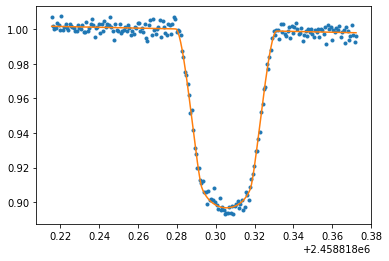

In [33]:
transit_params_opt=result.x[:4]
sys_params_opt=result.x[4:]

transit_model_opt=transit_model(transit_params_opt, P_pr.n, u1,u2, time)
sys_model_opt = sys_model(sys_params_opt,time)

pl.plot(time,flux,'.')
pl.plot(time, sys_model_opt * transit_model_opt)


# MCMC

In [34]:
def logprob(params_full):
    return -obj (params_full, u1, u2, time, flux, err)

In [35]:
import emcee
params  = params_full_pr

dim = len(params)
nwalkers = 100

In [36]:
nsteps=10000
pos0 = [params + 1e-7 * np.random.randn(dim) for i in range(nwalkers)]

sampler = emcee.EnsembleSampler(nwalkers, dim, logprob)
sampler.run_mcmc(pos0, nsteps, progress=True)

100%|██████████| 10000/10000 [22:08<00:00,  8.21it/s]


State([[ 2.45881831e+06  9.83060141e+00  3.45969587e-01  3.02536093e-01
   1.00153575e+00 -2.29049024e-02]
 [ 2.45881831e+06  9.85866108e+00  3.32452935e-01  3.01509290e-01
   1.00172189e+00 -2.33224262e-02]
 [ 2.45881831e+06  9.83255325e+00  3.50221087e-01  3.02261700e-01
   1.00134920e+00 -2.20621620e-02]
 [ 2.45881831e+06  9.86163760e+00  3.32217522e-01  3.01730291e-01
   1.00129947e+00 -1.83209798e-02]
 [ 2.45881831e+06  9.77269313e+00  3.59254779e-01  3.02254374e-01
   1.00177004e+00 -2.56224403e-02]
 [ 2.45881831e+06  9.89904944e+00  3.31399590e-01  3.01897677e-01
   1.00154608e+00 -2.31227376e-02]
 [ 2.45881831e+06  9.91304004e+00  3.24173622e-01  3.02043698e-01
   1.00184345e+00 -2.66034334e-02]
 [ 2.45881831e+06  9.87942831e+00  3.24510346e-01  3.01125718e-01
   1.00131323e+00 -2.02593727e-02]
 [ 2.45881831e+06  9.75473975e+00  3.64788266e-01  3.02755070e-01
   1.00124633e+00 -1.96463157e-02]
 [ 2.45881831e+06  9.94391862e+00  3.05247943e-01  3.00800224e-01
   1.00161614e+00 -

In [37]:
sampler.chain.shape

(100, 10000, 6)

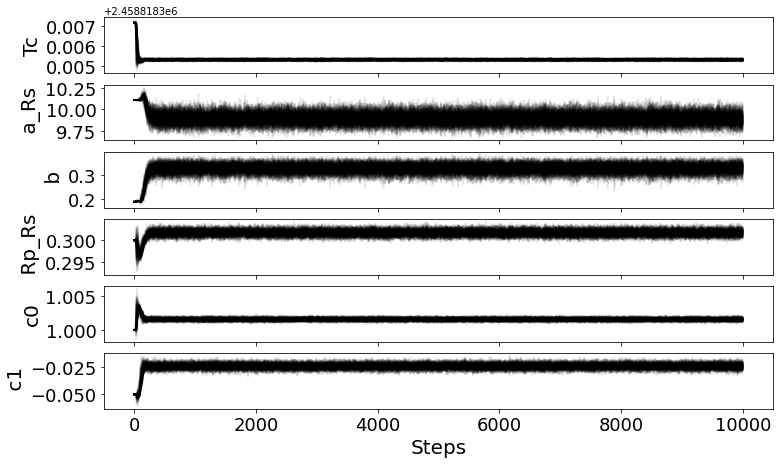

In [38]:
fig, ax = pl.subplots(dim, 1, figsize=(10*1.2,dim*1.2))

for i in range(dim):
    ax[i].plot(sampler.chain[:,:,i].T, color='k', alpha=0.1)
    
    if i==(dim-1):
        pl.setp(ax[i].get_xticklabels(), visible=True, fontsize=18)
        ax[i].set_xlabel('Steps', fontsize=20)
    else:
        pl.setp(ax[i].get_xticklabels(), visible=False)
    
    pl.setp(ax[i].get_yticklabels(), fontsize=18)
    ax[i].set_ylabel(params_name[i],fontsize=20)

In [39]:
sampler.acceptance_fraction

array([0.5226, 0.5227, 0.5211, 0.5041, 0.5185, 0.5245, 0.5084, 0.5066,
       0.5233, 0.5185, 0.5115, 0.5203, 0.5193, 0.5195, 0.5202, 0.5113,
       0.513 , 0.5114, 0.5183, 0.5083, 0.5067, 0.5183, 0.5246, 0.5154,
       0.5066, 0.5141, 0.5189, 0.5189, 0.5169, 0.5156, 0.5076, 0.5133,
       0.515 , 0.5111, 0.5171, 0.5171, 0.5138, 0.5249, 0.5125, 0.5174,
       0.5194, 0.5078, 0.5143, 0.5147, 0.5153, 0.5118, 0.5108, 0.5194,
       0.5144, 0.5076, 0.5112, 0.5127, 0.5047, 0.5166, 0.5037, 0.5093,
       0.5164, 0.5264, 0.5095, 0.5202, 0.5197, 0.5194, 0.5221, 0.5162,
       0.5139, 0.5216, 0.518 , 0.5181, 0.5171, 0.521 , 0.5119, 0.5164,
       0.5169, 0.5147, 0.5142, 0.5203, 0.5109, 0.5162, 0.5028, 0.5131,
       0.5129, 0.515 , 0.5094, 0.5204, 0.5119, 0.5077, 0.5181, 0.509 ,
       0.5185, 0.5259, 0.5184, 0.5113, 0.508 , 0.5159, 0.519 , 0.5161,
       0.5158, 0.5152, 0.5034, 0.5179])

In [40]:
samples=sampler.chain[:,1000:, :].reshape(-1,dim)
samples.shape

(900000, 6)

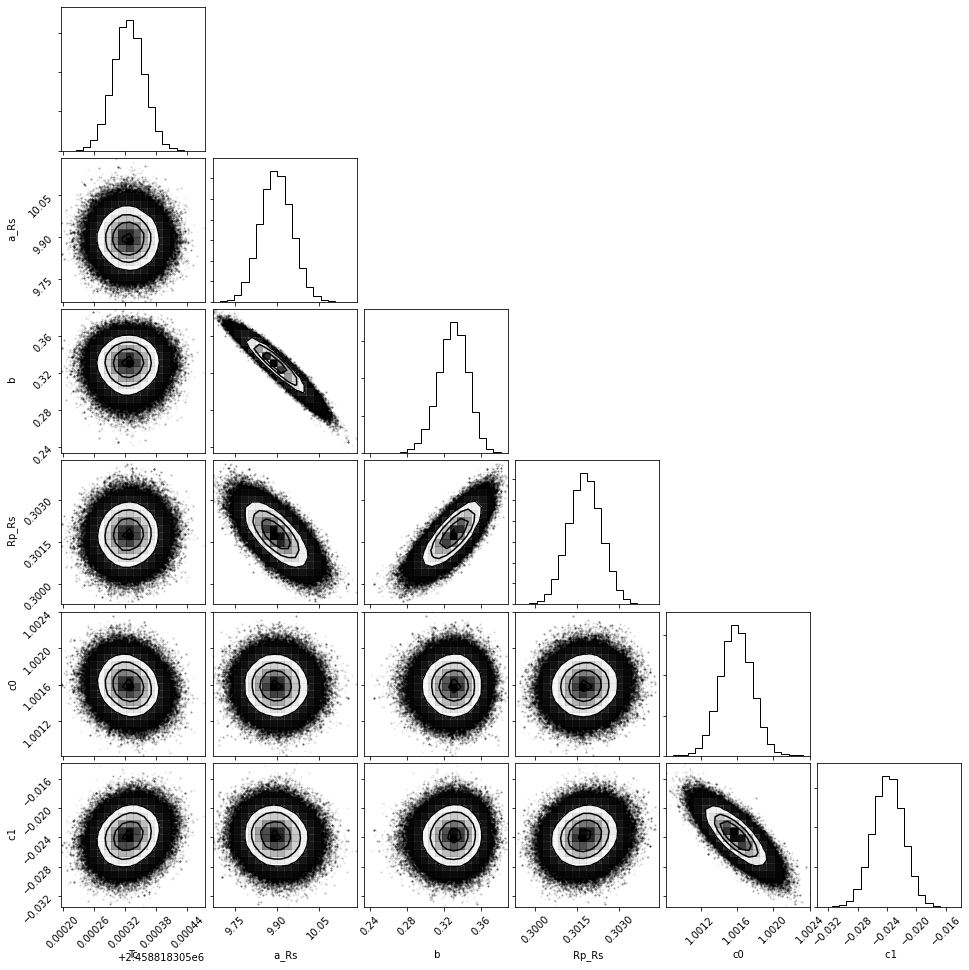

In [41]:
import corner

fig = corner.corner(samples, fontsize=10, labels=params_name)

In [42]:
df_chain= pd.DataFrame(samples)
df_chain.columns = params_name
df_chain.head()

,Tc,a_Rs,b,Rp_Rs,c0,c1
0,2.458818e+06,9.874510,0.333217,0.301531,1.001691,-0.027230
1,2.458818e+06,9.874510,0.333217,0.301531,1.001691,-0.027230
2,2.458818e+06,9.874510,0.333217,0.301531,1.001691,-0.027230
3,2.458818e+06,9.874878,0.333214,0.301532,1.001693,-0.027210
4,2.458818e+06,9.888364,0.329512,0.301457,1.001664,-0.026638


In [43]:
best_params=list(np.zeros_like(params_full_pr))
best_params_err1=list(np.zeros_like(params_full_pr))
best_params_err2=list(np.zeros_like(params_full_pr))

best_params_err1l=list(np.zeros_like(params_full_pr))
best_params_err1h=list(np.zeros_like(params_full_pr))
best_params_err2l=list(np.zeros_like(params_full_pr))
best_params_err2h=list(np.zeros_like(params_full_pr))

params_before=params_full_pr

for i in range(len(params_name)):
    A,B,C,D,E=np.percentile(df_chain[params_name[i]], [ 2.5, 16, 50, 84, 97.5], axis=0)
    
    del1l =C-B   #1sigma
    del1h=D-C
    del2l=C-A   #2sigma
    del2h=E-C 
    
    best_params[i]=C
    best_params_err1[i]=max(del1l,del1h)
    best_params_err2[i]=max(del2l,del2h)
    
    best_params_err1l[i]=del1l
    best_params_err1h[i]=del1h
    best_params_err2l[i]=del2l
    best_params_err2h[i]=del2h
    
    
df_result=pd.DataFrame({'after':best_params,'before':params_full_pr,'params_name':params_name,'err_after':best_params_err1})
df_result=df_result.set_index(['params_name'])
df_result=df_result[['before','after','err_after']]
df_result

,before,after,err_after
params_name,,,
Tc,2.458818e+06,2.458818e+06,0.000029
a_Rs,1.011000e+01,9.895617e+00,0.057098
b,1.900000e-01,3.296192e-01,0.016319
Rp_Rs,3.000000e-01,3.017616e-01,0.000581
c0,1.000000e+00,1.001588e+00,0.000170
c1,-5.000000e-02,-2.383111e-02,0.002066


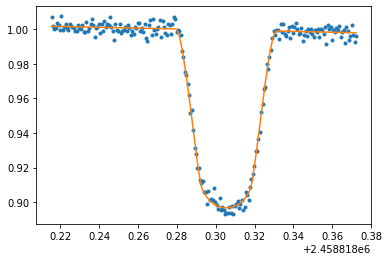

In [66]:
transit_params_best=best_params[:4]
sys_params_best=best_params[4:]

transit_model_best=transit_model(transit_params_best, P_pr.n, u1,u2, time)
sys_model_best = sys_model(sys_params_best,time)

pl.plot(time,flux,'.')
pl.plot(time, sys_model_best * transit_model_best)